# Recipe Site Traffic: Predicting High-Traffic Recipes for the Homepage

> **Note:** This project was completed as the **practical exam for the DataCamp Data Scientist Professional Certification** (case study *Recipe Site Traffic*, version 2212). The business scenario and dataset come from DataCamp. The analysis, modelling and recommendations are my own work.

**Author:** Joko Eliyanto
**Stakeholder:** Product Manager, Homepage Recipe Selection

The goal of this notebook is to decide whether a model can pick homepage recipes that drive high traffic. It runs in order: data loading, validation and cleaning, exploratory analysis, model fitting, evaluation and business recommendation.

## Library Import

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, precision_recall_curve,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                     cross_val_predict, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

# Global settings
RANDOM_STATE = 42
TARGET_PRECISION = 0.80          # business requirement from the product manager
NUTR_COLS = ["calories", "carbohydrate", "sugar", "protein"]

pd.set_option("display.float_format", "{:.2f}".format)
sns.set_theme(style="whitegrid", font_scale=1.1)
PALETTE = {"High": "#1f4e79", "Low": "#9dc3e6"}
ACCENT = "#c55a11"

## 1. Load Data & Data Documentation

In [2]:
df = pd.read_csv("../data/recipe_site_traffic_2212.csv")
print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")
df.head(10)

Rows: 947 | Columns: 8


,recipe,calories,carbohydrate,sugar,protein,category,servings,high_traffic
0,1,NaN,NaN,NaN,NaN,Pork,6,High
1,2,35.48,38.56,0.66,0.92,Potato,4,High
2,3,914.28,42.68,3.09,2.88,Breakfast,1,NaN
3,4,97.03,30.56,38.63,0.02,Beverages,4,High
4,5,27.05,1.85,0.80,0.53,Beverages,4,NaN
5,6,691.15,3.46,1.65,53.93,One Dish Meal,2,High
6,7,183.94,47.95,9.75,46.71,Chicken Breast,4,NaN
7,8,299.14,3.17,0.40,32.40,Lunch/Snacks,4,NaN
8,9,538.52,3.78,3.37,3.79,Pork,6,High
9,10,248.28,48.54,3.99,113.85,Chicken,2,NaN


**Data documentation**

| Column | Details |
|---|---|
| `recipe` | Numeric, unique identifier of recipe |
| `calories` | Numeric, number of calories |
| `carbohydrate` | Numeric, amount of carbohydrates in grams |
| `sugar` | Numeric, amount of sugar in grams |
| `protein` | Numeric, amount of protein in grams |
| `category` | Character, type of recipe. One of ten groupings: 'Lunch/Snacks', 'Beverages', 'Potato', 'Vegetable', 'Meat', 'Chicken', 'Pork', 'Dessert', 'Breakfast', 'One Dish Meal' |
| `servings` | Numeric, number of servings for the recipe |
| `high_traffic` | Character, marked "High" if traffic to the site was high when this recipe was shown |

## 2. Business Problem Definition

The product manager currently picks the homepage recipe by personal preference. When the chosen recipe is popular, **traffic to the rest of the website rises by up to 40%**, and more traffic leads to more subscriptions. There is no systematic way to tell in advance whether a recipe will be popular.

The task is a **binary classification** problem: using the recipe's nutrition, category and servings, predict whether showing it on the homepage leads to **High** traffic.

The most costly error is showing a recipe predicted as High that turns out to be Low. That wastes a homepage slot and the traffic uplift it could have brought. The key metric is therefore **precision on the High class**: of the recipes the model recommends, how many are actually high-traffic.

## 3. Objective

1. **Predict which recipes will lead to high traffic.**
2. **Correctly predict high-traffic recipes at least 80% of the time**, measured as precision on the High class (≥ 0.80) on unseen data.
3. Translate the result into a business KPI and a recommendation for next steps.

**Success criteria:** the selected model must beat the current baseline (the share of High recipes in the data, which is what a random pick achieves) and reach precision ≥ 0.80 on the hold-out test set.

## 4. Data Validation & Data Cleaning

In [3]:
df_clean = df.copy()

### 4.1 Data Type Validation

In [4]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 947 entries, 0 to 946
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   recipe        947 non-null    int64  
 1   calories      895 non-null    float64
 2   carbohydrate  895 non-null    float64
 3   sugar         895 non-null    float64
 4   protein       895 non-null    float64
 5   category      947 non-null    str    
 6   servings      947 non-null    str    
 7   high_traffic  574 non-null    str    
dtypes: float64(4), int64(1), str(3)
memory usage: 59.3 KB


| Column | Documented type | Dtype in data | Status | Action |
|---|---|---|---|---|
| `recipe` | Numeric | int64 | Match | None |
| `calories`, `carbohydrate`, `sugar`, `protein` | Numeric | float64 | Match | Missing values handled in 4.3 |
| `category` | Character | str | Match | Clean values, convert to `category` |
| `servings` | **Numeric** | **str** | **Mismatch** | Extract digits, convert to `int64` |
| `high_traffic` | Character | str | Match | Fill missing values, convert to `category` |

In [5]:
print(df_clean["servings"].value_counts())

non_numeric = ~df_clean["servings"].astype(str).str.fullmatch(r"\d+")
print("\nRows with non-numeric servings:", non_numeric.sum())
df_clean.loc[non_numeric, ["recipe", "servings"]]

servings
4               389
6               197
2               183
1               175
4 as a snack      2
6 as a snack      1
Name: count, dtype: int64

Rows with non-numeric servings: 3


,recipe,servings
451,452,4 as a snack
548,549,6 as a snack
735,736,4 as a snack


**Finding:** `servings` is stored as text because 3 of 947 rows (0.3%) contain the suffix *"as a snack"* (e.g. "4 as a snack"). The number is still valid, so the digits are kept and the column is converted to integer.

In [6]:
df_clean["servings"] = (
    df_clean["servings"].astype(str).str.extract(r"^(\d+)")[0].astype("int64")
)
print("Dtype:", df_clean["servings"].dtype)
print(df_clean["servings"].value_counts().sort_index())

Dtype: int64
servings
1    175
2    183
4    391
6    198
Name: count, dtype: int64


### 4.2 Data Duplication

In [7]:
print("Duplicate rows             :", df_clean.duplicated().sum())
print("Recipe ID is unique        :", df_clean["recipe"].is_unique)
print("Duplicates ignoring the ID :", df_clean.drop(columns="recipe").duplicated().sum())

Duplicate rows             : 0
Recipe ID is unique        : True
Duplicates ignoring the ID : 23


**Finding:** there are no duplicate rows and every `recipe` ID is unique, so no rows are removed.

### 4.3 Missing Value

In [8]:
missing = pd.DataFrame({
    "missing": df_clean.isna().sum(),
    "pct": df_clean.isna().mean().mul(100).round(1),
})
missing[missing["missing"] > 0]

,missing,pct
calories,52,5.50
carbohydrate,52,5.50
sugar,52,5.50
protein,52,5.50
high_traffic,373,39.40


In [9]:
# Are the nutrition values missing in the same rows?
nutr_missing = df_clean[NUTR_COLS].isna()
print("Rows missing ALL nutrition values:", nutr_missing.all(axis=1).sum())
print("Rows missing ANY nutrition value :", nutr_missing.any(axis=1).sum())

Rows missing ALL nutrition values: 52
Rows missing ANY nutrition value : 52


**Findings**

1. **Nutrition columns:** 52 recipes (5.5%) are missing all four nutrition values at once, which points to recipes that were never fully entered. The distributions are right-skewed, so the gaps are filled with the **median of the recipe's category**, which respects nutritional differences between, for example, beverages and meat. No rows are dropped.
2. **`high_traffic`:** 373 values (39.4%) are missing. The documentation says only high-traffic recipes are marked "High", so a missing value means **not high**. It is filled with `"Low"`.

In [10]:
# 1. Nutrition: median per category (category is cleaned first so 'Chicken Breast' joins 'Chicken')
df_clean["category"] = df_clean["category"].str.strip().replace({"Chicken Breast": "Chicken"})
for col in NUTR_COLS:
    df_clean[col] = df_clean.groupby("category")[col].transform(lambda s: s.fillna(s.median()))

# 2. Target: missing means "not High"
df_clean["high_traffic"] = df_clean["high_traffic"].fillna("Low")

print("Missing values after handling:", int(df_clean.isna().sum().sum()))
print("Rows kept:", len(df_clean))

# Imputation should not distort the distributions
pd.concat({"before": df[NUTR_COLS].median(), "after": df_clean[NUTR_COLS].median()}, axis=1).T

Missing values after handling: 0
Rows kept: 947


,calories,carbohydrate,sugar,protein
before,288.55,21.48,4.55,10.80
after,296.92,21.19,4.40,11.24


**Result:** no missing values remain, all 947 rows are kept, and the medians barely change. The imputation did not distort the distributions.

### 4.4 Numerical Data Validation

In [11]:
df_clean[NUTR_COLS + ["servings"]].describe().T

,count,mean,std,min,25%,50%,75%,max
calories,947.00,431.09,441.37,0.14,114.41,296.92,576.23,3633.16
carbohydrate,947.00,34.45,42.85,0.03,9.13,21.19,42.59,530.42
sugar,947.00,8.89,14.37,0.01,1.79,4.40,9.57,148.75
protein,947.00,23.94,35.47,0.00,3.46,11.24,29.82,363.36
servings,947.00,3.48,1.73,1.00,2.00,4.00,4.00,6.00


In [12]:
# Negative values are impossible for nutrition and servings
print("Negative values:", int((df_clean[NUTR_COLS + ["servings"]] < 0).sum().sum()))

# Outliers by the IQR rule (reported, not removed)
q1, q3 = df_clean[NUTR_COLS].quantile(0.25), df_clean[NUTR_COLS].quantile(0.75)
outliers = ((df_clean[NUTR_COLS] > q3 + 1.5 * (q3 - q1))).sum()
outliers.to_frame("IQR outliers").assign(pct=lambda d: (d["IQR outliers"] / len(df_clean) * 100).round(1))

Negative values: 0


,IQR outliers,pct
calories,58,6.10
carbohydrate,66,7.00
sugar,85,9.00
protein,84,8.90


**Findings**

- There are **no negative values**. All nutrition values and servings fall in a valid range, and `servings` takes only the values 1, 2, 4 and 6.
- All four nutrition columns are **strongly right-skewed** (mean well above median). Between 6% and 9% of each column are IQR outliers, but values such as 3,600 calories are plausible for large, multi-serving recipes. They are **kept**, and the skew is handled with a log transform in modelling.

### 4.5 Categorical Data Validation

In [13]:
VALID_CATEGORIES = ["Lunch/Snacks", "Beverages", "Potato", "Vegetable", "Meat",
                    "Chicken", "Pork", "Dessert", "Breakfast", "One Dish Meal"]

print("Raw categories:", df["category"].nunique(), "(documentation says 10)")
print("Not in documentation:", set(df["category"].unique()) - set(VALID_CATEGORIES))
print("Clean categories:", df_clean["category"].nunique())
assert df_clean["category"].isin(VALID_CATEGORIES).all()

print("\nTarget values:", df_clean["high_traffic"].unique().tolist())

df_clean["category"] = pd.Categorical(df_clean["category"], categories=VALID_CATEGORIES)
df_clean["high_traffic"] = pd.Categorical(df_clean["high_traffic"], categories=["High", "Low"])
df_clean.info()

Raw categories: 11 (documentation says 10)
Not in documentation: {'Chicken Breast'}
Clean categories: 10

Target values: ['High', 'Low']
<class 'pandas.DataFrame'>
RangeIndex: 947 entries, 0 to 946
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   recipe        947 non-null    int64   
 1   calories      947 non-null    float64 
 2   carbohydrate  947 non-null    float64 
 3   sugar         947 non-null    float64 
 4   protein       947 non-null    float64 
 5   category      947 non-null    category
 6   servings      947 non-null    int64   
 7   high_traffic  947 non-null    category
dtypes: category(2), float64(4), int64(2)
memory usage: 46.9 KB


**Finding:** the raw data contains 11 categories. The extra label **"Chicken Breast"** (98 recipes) is not in the documentation and was merged into **"Chicken"** (already applied in 4.3 so that imputation used the right group). The data now has exactly the 10 documented categories, and the target holds only "High" / "Low".

**Cleaned dataset:** 947 rows × 8 columns, no missing values, no duplicates, all types match the documentation.

## 5. Exploratory Data Analysis (EDA)

The EDA focuses on one question: **what separates recipes that drive high traffic from those that do not?**

### 5.1 Target Variable: Traffic Level

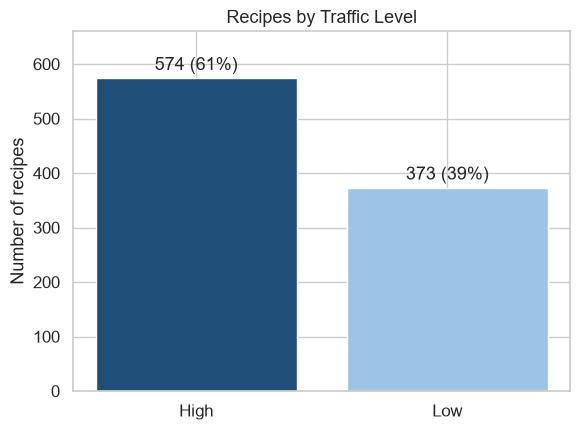

In [14]:
counts = df_clean["high_traffic"].value_counts().reindex(["High", "Low"])
fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(counts.index, counts.values, color=[PALETTE["High"], PALETTE["Low"]])
ax.bar_label(bars, labels=[f"{v} ({v / counts.sum():.0%})" for v in counts.values], padding=3)
ax.set_title("Recipes by Traffic Level")
ax.set_ylabel("Number of recipes")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.show()

**Insight:** 574 of 947 recipes (**60.6%**) generated high traffic. This is the **benchmark to beat**: picking a recipe at random, or by personal preference without a data signal, gives roughly a 61% chance of a high-traffic day. The goal of 80% means lifting the hit rate by about 20 percentage points. The classes are only mildly imbalanced, so a stratified split is enough and no resampling is needed.

### 5.2 Recipe Category vs High Traffic

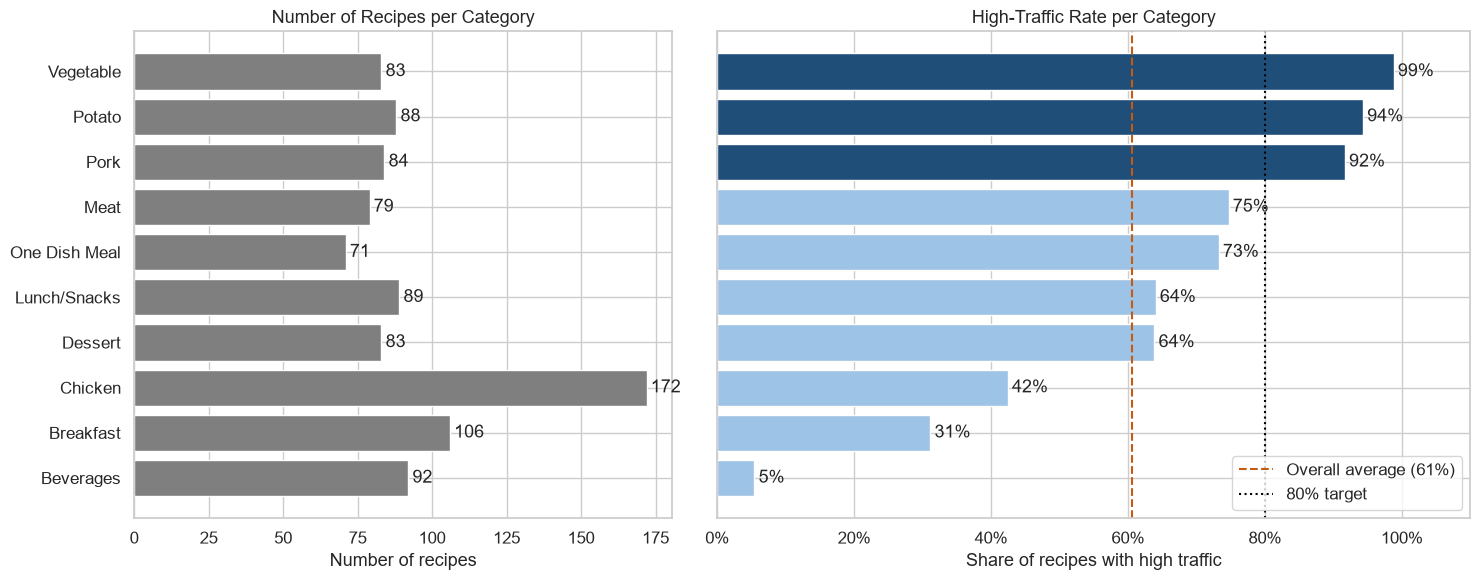

,recipes,high_rate
category,,
Vegetable,83,0.99
Potato,88,0.94
Pork,84,0.92
Meat,79,0.75
One Dish Meal,71,0.73
Lunch/Snacks,89,0.64
Dessert,83,0.64
Chicken,172,0.42
Breakfast,106,0.31


In [15]:
cat_stats = (df_clean.assign(is_high=df_clean["high_traffic"].eq("High"))
             .groupby("category", observed=True)["is_high"]
             .agg(recipes="size", high_rate="mean")
             .sort_values("high_rate"))
overall_rate = df_clean["high_traffic"].eq("High").mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True,
                         gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].barh(cat_stats.index, cat_stats["recipes"], color="#7f7f7f")
axes[0].bar_label(axes[0].containers[0], padding=3)
axes[0].set_title("Number of Recipes per Category")
axes[0].set_xlabel("Number of recipes")

colors = [PALETTE["High"] if r >= TARGET_PRECISION else PALETTE["Low"] for r in cat_stats["high_rate"]]
axes[1].barh(cat_stats.index, cat_stats["high_rate"], color=colors)
axes[1].bar_label(axes[1].containers[0], labels=[f"{r:.0%}" for r in cat_stats["high_rate"]], padding=3)
axes[1].axvline(overall_rate, color=ACCENT, ls="--", label=f"Overall average ({overall_rate:.0%})")
axes[1].axvline(TARGET_PRECISION, color="black", ls=":", label="80% target")
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set_xlim(0, 1.1)
axes[1].set_title("High-Traffic Rate per Category")
axes[1].set_xlabel("Share of recipes with high traffic")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()
cat_stats.sort_values("high_rate", ascending=False)

**Insight: category is the strongest driver of traffic.**

- **Vegetable (99%), Potato (94%) and Pork (92%)** are almost always high-traffic and are the only categories above the 80% target by themselves. Meat (75%) and One Dish Meal (73%) also beat the average.
- **Beverages (5%), Breakfast (31%) and Chicken (42%)** perform far below the 61% average. Beverages are close to a guaranteed low-traffic day.
- Chicken is the largest category (172 recipes after the merge) but converts below average. **Being well-stocked in the catalogue does not mean a category attracts homepage visitors.**

*Business implication:* even a simple rule such as "avoid Beverages and Breakfast on the homepage" would lift the hit rate. A model can go further by ranking recipes **within** categories.

### 5.3 Nutrition Distribution

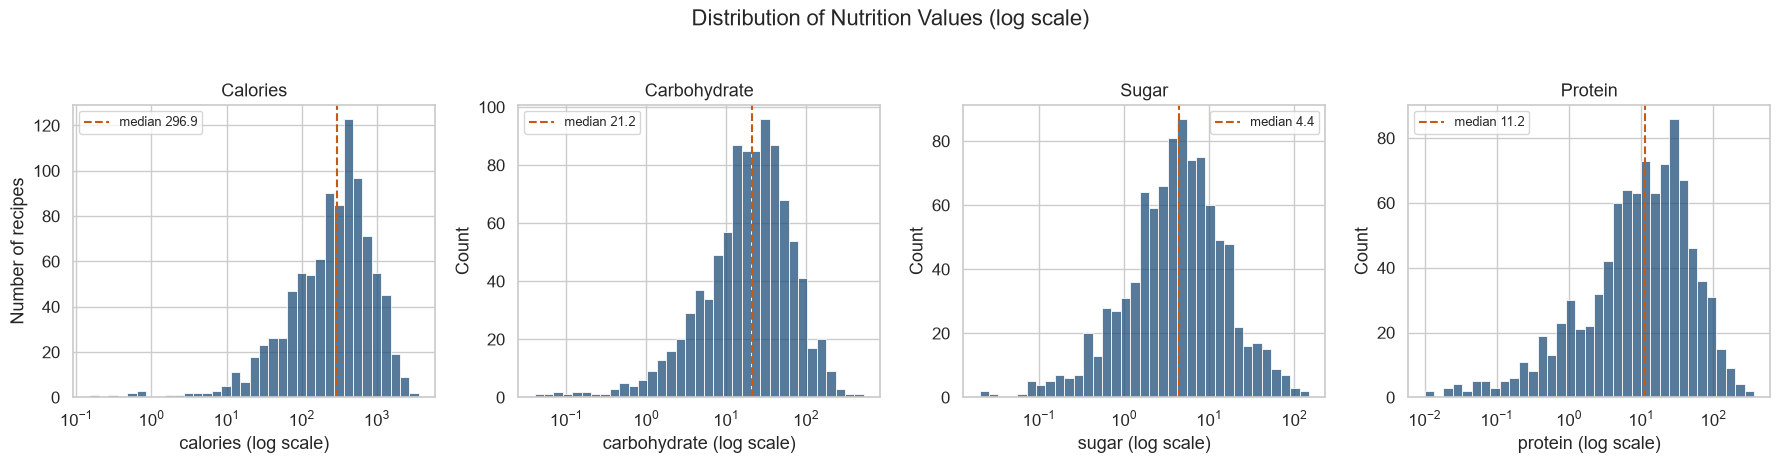

,calories,carbohydrate,sugar,protein
skewness,2.11,3.87,4.29,3.59


In [16]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, col in zip(axes, NUTR_COLS):
    sns.histplot(df_clean[col] + 0.01, bins=35, log_scale=True, color=PALETTE["High"], ax=ax)
    ax.axvline(df_clean[col].median(), color=ACCENT, ls="--", label=f"median {df_clean[col].median():.1f}")
    ax.set_title(col.capitalize())
    ax.set_xlabel(f"{col} (log scale)")
    ax.legend(fontsize=9)
axes[0].set_ylabel("Number of recipes")
fig.suptitle("Distribution of Nutrition Values (log scale)", y=1.03)
plt.tight_layout()
plt.show()

df_clean[NUTR_COLS].skew().to_frame("skewness").T

**Insight:** all four nutrition features are heavily right-skewed (skewness 2.1–4.3). Most recipes are moderate (median ~290 kcal), with a long tail of very large recipes. On the log scale the distributions look close to normal, which is why the linear model uses a **log transform**. Without it, a few extreme recipes would dominate the fit.

### 5.4 Nutrition vs Traffic Level

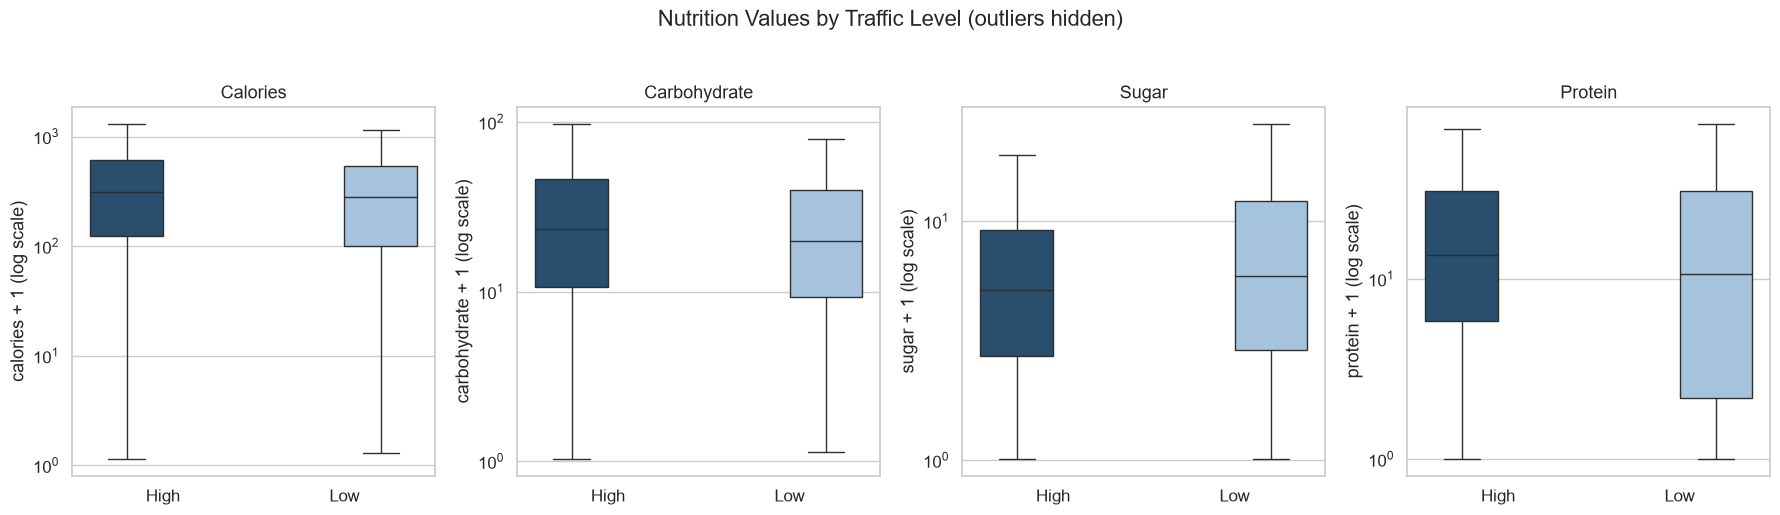

,calories,carbohydrate,sugar,protein
high_traffic,,,,
High,313.92,22.55,4.17,12.52
Low,282.57,18.84,4.93,9.62


In [17]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, col in zip(axes, NUTR_COLS):
    sns.boxplot(x=df_clean["high_traffic"], y=df_clean[col] + 1, hue=df_clean["high_traffic"],
                order=["High", "Low"], palette=PALETTE, legend=False, showfliers=False, ax=ax)
    ax.set_yscale("log")
    ax.set_title(col.capitalize())
    ax.set_xlabel("")
    ax.set_ylabel(f"{col} + 1 (log scale)")
fig.suptitle("Nutrition Values by Traffic Level (outliers hidden)", y=1.03)
plt.tight_layout()
plt.show()

df_clean.groupby("high_traffic", observed=True)[NUTR_COLS].median()

**Insight:** the nutrition profiles of High and Low recipes **overlap heavily**. High-traffic recipes have slightly more calories, carbohydrates and protein (median protein 12.5 g vs 9.6 g) and a little less sugar, but the gaps are small compared with the spread. **Nutrition alone cannot tell a popular recipe from an unpopular one.** It mostly adds fine-tuning on top of the category signal, and much of that signal comes from category itself (sweet beverages vs hearty, protein-rich mains).

### 5.5 Servings vs Traffic Level

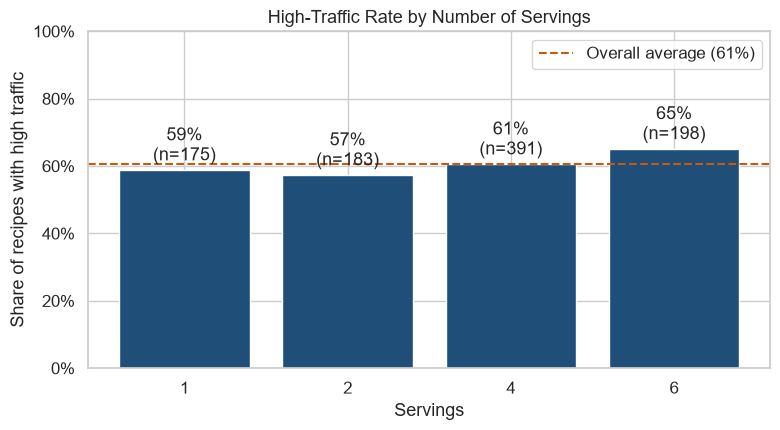

In [18]:
serv = (df_clean.assign(is_high=df_clean["high_traffic"].eq("High"))
        .groupby("servings")["is_high"].agg(recipes="size", high_rate="mean"))

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(serv.index.astype(str), serv["high_rate"], color=PALETTE["High"])
ax.bar_label(bars, labels=[f"{r:.0%}\n(n={n})" for r, n in zip(serv["high_rate"], serv["recipes"])], padding=3)
ax.axhline(overall_rate, color=ACCENT, ls="--", label=f"Overall average ({overall_rate:.0%})")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 1)
ax.set_title("High-Traffic Rate by Number of Servings")
ax.set_xlabel("Servings")
ax.set_ylabel("Share of recipes with high traffic")
ax.legend()
plt.tight_layout()
plt.show()

**Insight:** the number of servings has **almost no effect** on traffic. The high-traffic rate stays between 57% and 65% for 1, 2, 4 and 6 servings, all close to the 61% average. Portion size is not a lever for homepage selection. The feature is kept in the model but is not expected to matter much.

### 5.6 Correlation Between Numerical Features

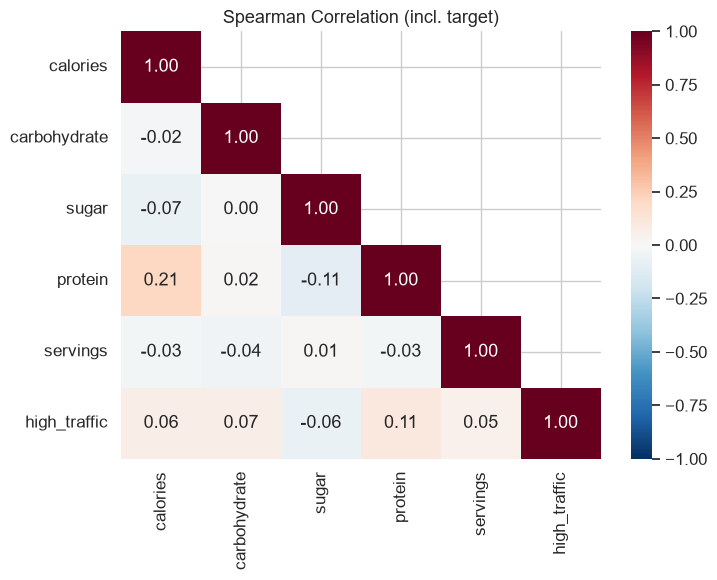

In [19]:
corr = (df_clean[NUTR_COLS + ["servings"]]
        .assign(high_traffic=df_clean["high_traffic"].eq("High").astype(int))
        .corr(method="spearman"))

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1), ax=ax)
ax.set_title("Spearman Correlation (incl. target)")
plt.tight_layout()
plt.show()

**Insight:** all numerical features have **weak correlations with high traffic** (|ρ| ≤ 0.11; protein is the strongest at 0.11) and weak correlations with each other (the highest is calories–protein at 0.21). This means:

1. There is **no multicollinearity** problem, so all features can enter the model together.
2. The predictive power comes mainly from **category**, which confirms what 5.2 showed.

### EDA Summary

| Finding | Business meaning |
|---|---|
| 60.6% of recipes are High traffic | A random pick hits ~61% of the time; this is the benchmark |
| Vegetable, Potato and Pork are ≥ 92% High | Safe categories for the homepage |
| Beverages (5%), Breakfast (31%) and Chicken (42%) are mostly Low | Categories to avoid or show only with strong model support |
| Nutrition and servings have weak signal | They help rank recipes within a category but do not drive traffic on their own |

The data suggests that a model combining **category** with nutrition can separate High from Low recipes well enough to approach the 80% target.

## 6. Model Fitting

**Approach**

- **Problem type:** binary classification (High = 1, Low = 0).
- **Features:** `calories`, `carbohydrate`, `sugar`, `protein`, `servings` and `category` (one-hot encoded). `recipe` is an ID and is excluded.
- **Preprocessing:** log transform plus scaling of the skewed nutrition features for the linear model. Tree models use the raw values.
- **Models:** **Logistic Regression** as the baseline (simple, interpretable), compared with **Random Forest**, **Gradient Boosting** and **XGBoost**. A **Dummy classifier** (always predicts "High") represents a random homepage pick.
- **Validation:** stratified 80/20 train/test split. Hyperparameters are tuned with 5-fold stratified cross-validation **on the training set only**, optimised for ROC-AUC (how well the model *ranks* recipes).
- **Business threshold:** instead of the default 0.5 cut-off, the decision threshold is chosen on out-of-fold training predictions so that **precision ≥ 80%** with the highest possible recall. The test set is used only once, for the final evaluation.

In [20]:
X = df_clean[NUTR_COLS + ["servings", "category"]].copy()
X["category"] = X["category"].astype(str)
y = df_clean["high_traffic"].eq("High").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows | High share: {y.mean():.1%}")

Train: 757 rows | Test: 190 rows | High share: 60.6%


In [21]:
prep_linear = ColumnTransformer([
    ("nutr", Pipeline([("log", FunctionTransformer(np.log1p)), ("scale", StandardScaler())]), NUTR_COLS),
    ("serv", StandardScaler(), ["servings"]),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["category"]),
])
prep_tree = ColumnTransformer([
    ("num", "passthrough", NUTR_COLS + ["servings"]),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["category"]),
])

candidates = {
    "Logistic Regression (baseline)": (
        Pipeline([("prep", prep_linear), ("model", LogisticRegression(max_iter=2000))]),
        {"model__C": [0.01, 0.1, 0.3, 1, 3, 10]}),
    "Random Forest": (
        Pipeline([("prep", prep_tree), ("model", RandomForestClassifier(random_state=RANDOM_STATE))]),
        {"model__n_estimators": [300], "model__max_depth": [4, 6, 8, None],
         "model__min_samples_leaf": [1, 5, 10]}),
    "Gradient Boosting": (
        Pipeline([("prep", prep_tree), ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))]),
        {"model__n_estimators": [100, 200], "model__learning_rate": [0.05, 0.1],
         "model__max_depth": [2, 3]}),
    "XGBoost": (
        Pipeline([("prep", prep_tree), ("model", XGBClassifier(eval_metric="logloss", n_jobs=1,
                                                                random_state=RANDOM_STATE))]),
        {"model__n_estimators": [100, 300], "model__learning_rate": [0.03, 0.1],
         "model__max_depth": [2, 3, 4]}),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models, cv_rows = {}, []
for name, (pipe, grid) in candidates.items():
    gs = GridSearchCV(pipe, grid, cv=cv, scoring=["roc_auc", "precision", "accuracy"],
                      refit="roc_auc", n_jobs=-1).fit(X_train, y_train)
    models[name] = gs.best_estimator_
    i = gs.best_index_
    cv_rows.append({"Model": name,
                    "CV ROC-AUC": gs.cv_results_["mean_test_roc_auc"][i],
                    "CV ROC-AUC std": gs.cv_results_["std_test_roc_auc"][i],
                    "CV Precision (0.5)": gs.cv_results_["mean_test_precision"][i],
                    "CV Accuracy": gs.cv_results_["mean_test_accuracy"][i],
                    "Best params": ", ".join(f"{k.split('__')[1]}={v}" for k, v in gs.best_params_.items())})

models["Dummy (always High)"] = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
cv_results = pd.DataFrame(cv_rows).set_index("Model").sort_values("CV ROC-AUC", ascending=False)
cv_results

,CV ROC-AUC,CV ROC-AUC std,CV Precision (0.5),CV Accuracy,Best params
Model,,,,,
XGBoost,0.82,0.04,0.78,0.75,"learning_rate=0.03, max_depth=3, n_estimators=100"
Random Forest,0.82,0.05,0.75,0.73,"max_depth=8, min_samples_leaf=10, n_estimators..."
Logistic Regression (baseline),0.81,0.04,0.79,0.76,C=1
Gradient Boosting,0.81,0.05,0.77,0.75,"learning_rate=0.05, max_depth=2, n_estimators=100"


**Insight:** all four models perform almost identically in cross-validation (**ROC-AUC 0.81–0.82**), and the differences are smaller than the fold-to-fold variation (±0.04–0.05). More complex tree-based models do **not** add meaningful predictive power over Logistic Regression, which is consistent with the EDA: the signal is mostly a simple, additive category effect.

Following the principle *choose the simplest model that performs as well as the best*, **Logistic Regression** is selected. It is also the easiest to explain to the business and to maintain in production. The selection is made on training data only, before looking at the test set.

In [22]:
# Selection rule (training data only): prefer the simplest model whose CV ROC-AUC
# is within one standard deviation of the best model.
BASE = "Logistic Regression (baseline)"
top = cv_results.iloc[0]
within_noise = cv_results.loc[BASE, "CV ROC-AUC"] >= top["CV ROC-AUC"] - top["CV ROC-AUC std"]
BEST = BASE if within_noise else cv_results.index[0]
print(f"Best CV ROC-AUC: {cv_results.index[0]} ({top['CV ROC-AUC']:.3f} ± {top['CV ROC-AUC std']:.3f})")
print(f"Baseline CV ROC-AUC: {cv_results.loc[BASE, 'CV ROC-AUC']:.3f} -> within noise: {within_noise}")
print("Selected model:", BEST)

Best CV ROC-AUC: XGBoost (0.819 ± 0.038)
Baseline CV ROC-AUC: 0.811 -> within noise: True
Selected model: Logistic Regression (baseline)


**Choosing a business-driven decision threshold**

The default cut-off of 0.5 is not tied to the business goal. For each model, out-of-fold probabilities on the **training data** are used to find the lowest threshold that still gives **precision ≥ 80%**. This keeps recall as high as possible, so there are enough candidate recipes for the homepage.

In [23]:
def threshold_for_precision(y_true, proba, target=TARGET_PRECISION):
    """Lowest threshold whose precision meets the target (maximises recall)."""
    prec, rec, thr = precision_recall_curve(y_true, proba)
    ok = np.where(prec[:-1] >= target)[0]
    return float(thr[ok[0]]) if len(ok) else 0.5

thresholds, oof = {}, {}
for name in cv_results.index:
    oof[name] = cross_val_predict(models[name], X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    thresholds[name] = threshold_for_precision(y_train, oof[name])

pd.Series(thresholds, name="Threshold for ≥80% precision (train, out-of-fold)").to_frame()

,"Threshold for ≥80% precision (train, out-of-fold)"
XGBoost,0.65
Random Forest,0.59
Logistic Regression (baseline),0.63
Gradient Boosting,0.65


## 7. Model Evaluation

All models are now scored **once** on the hold-out test set (190 recipes they have never seen), at both the default 0.5 threshold and the business threshold.

In [24]:
def evaluate(name, thr):
    proba = models[name].predict_proba(X_test)[:, 1]
    pred = (proba >= thr).astype(int)
    return {"Threshold": thr,
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred),
            "Accuracy": accuracy_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "ROC-AUC": roc_auc_score(y_test, proba) if name in thresholds else np.nan,
            "Recipes flagged High": int(pred.sum())}

rows = []
for name in cv_results.index:
    rows.append({"Model": name, "Setting": "Default (0.5)", **evaluate(name, 0.5)})
    rows.append({"Model": name, "Setting": "Business (≥80% precision)", **evaluate(name, thresholds[name])})
rows.append({"Model": "Dummy (always High)", "Setting": "Random pick", **evaluate("Dummy (always High)", 0.5)})

test_results = pd.DataFrame(rows).set_index(["Model", "Setting"])
test_results

Threshold  \
Model                          Setting                                
XGBoost                        Default (0.5)                   0.50   
                               Business (≥80% precision)       0.65   
Random Forest                  Default (0.5)                   0.50   
                               Business (≥80% precision)       0.59   
Logistic Regression (baseline) Default (0.5)                   0.50   
                               Business (≥80% precision)       0.63   
Gradient Boosting              Default (0.5)                   0.50   
                               Business (≥80% precision)       0.65   
Dummy (always High)            Random pick                     0.50   

                                                          Precision  Recall  \
Model                          Setting                                        
XGBoost                        Default (0.5)                   0.85    0.77   
                               Business (≥80% precision)       0.85    0.77   
Random Forest                  Default (0.5)                   0.81    0.79   
                               Business (≥80% precision)       0.85    0.75   
Logistic Regression (baseline) Default (0.5)                   0.85    0.77   
                               Business (≥80% precision)       0.90    0.61   
Gradient Boosting              Default (0.5)                   0.85    0.77   
                               Business (≥80% precision)       0.86    0.65   
Dummy (always High)            Random pick                     0.61    1.00   

                                                          Accuracy   F1  \
Model                          Setting                                    
XGBoost                        Default (0.5)                  0.78 0.81   
                               Business (≥80% precision)      0.78 0.81   
Random Forest                  Default (0.5)                  0.76 0.80   
                               Business (≥80% precision)      0.77 0.80   
Logistic Regression (baseline) Default (0.5)                  0.78 0.81   
                               Business (≥80% precision)      0.72 0.73   
Gradient Boosting              Default (0.5)                  0.78 0.81   
                               Business (≥80% precision)      0.73 0.74   
Dummy (always High)            Random pick                    0.61 0.75   

                                                          ROC-AUC  \
Model                          Setting                              
XGBoost                        Default (0.5)                 0.86   
                               Business (≥80% precision)     0.86   
Random Forest                  Default (0.5)                 0.84   
                               Business (≥80% precision)     0.84   
Logistic Regression (baseline) Default (0.5)                 0.87   
                               Business (≥80% precision)     0.87   
Gradient Boosting              Default (0.5)                 0.85   
                               Business (≥80% precision)     0.85   
Dummy (always High)            Random pick                    NaN   

                                                          Recipes flagged High  
Model                          Setting                                          
XGBoost                        Default (0.5)                               105  
                               Business (≥80% precision)                   103  
Random Forest                  Default (0.5)                               112  
                               Business (≥80% precision)                   101  
Logistic Regression (baseline) Default (0.5)                               105  
                               Business (≥80% precision)                    78  
Gradient Boosting              Default (0.5)                               103  
                               Business (≥80% precision)                    87  
Dummy (alw

**Insight**

- **Every model clearly beats the random pick** (precision 0.60). Even at the default 0.5 threshold, all models reach precision 0.81–0.85, so the **80% target is met on unseen data**.
- The selected **Logistic Regression** has the **best test ROC-AUC (0.87)**, which confirms the CV-based choice. At the business threshold (0.63) its precision rises to **0.90**: 9 out of 10 recipes it recommends actually drive high traffic.
- The trade-off is recall: at the business threshold the model identifies 61% of all high-traffic recipes (78 of 190 test recipes are flagged). For homepage selection this is acceptable, because **only one recipe is needed per day**. Being right about the recipes we show matters more than finding every possible popular recipe.
- CV results (0.81–0.82 AUC) and test results (0.84–0.87) are consistent, so there is **no sign of overfitting**.

### 7.1 Model Comparison

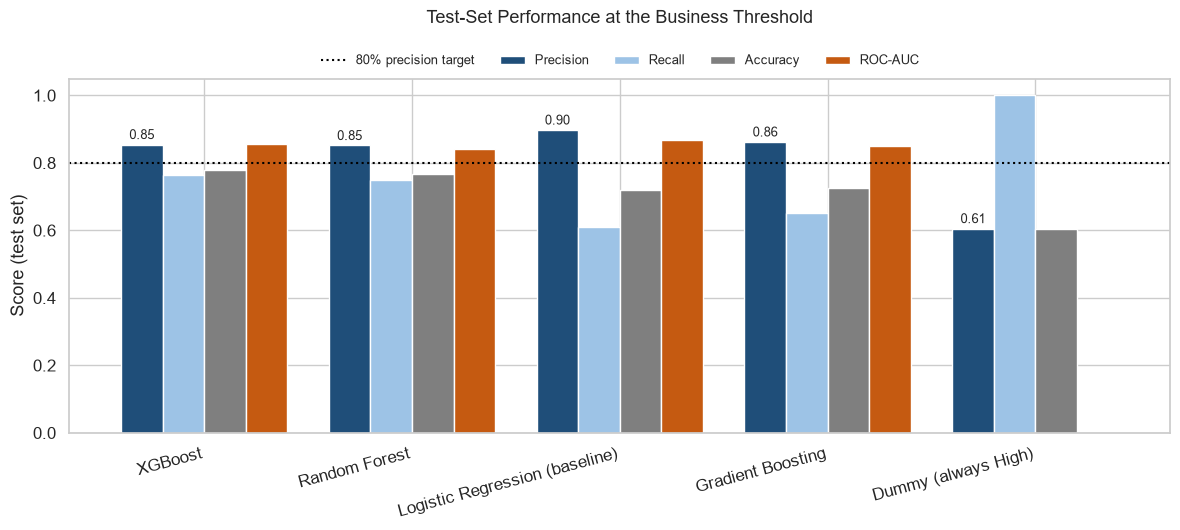

In [25]:
plot_df = test_results.xs("Business (≥80% precision)", level="Setting")[["Precision", "Recall", "Accuracy", "ROC-AUC"]]
plot_df.loc["Dummy (always High)"] = test_results.loc[("Dummy (always High)", "Random pick"), ["Precision", "Recall", "Accuracy", "ROC-AUC"]]

ax = plot_df.plot(kind="bar", figsize=(12, 5.5), width=0.8,
                  color=["#1f4e79", "#9dc3e6", "#7f7f7f", ACCENT])
ax.axhline(TARGET_PRECISION, color="black", ls=":", label="80% precision target")
for c in ax.containers[:1]:
    ax.bar_label(c, fmt="%.2f", padding=2, fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score (test set)")
ax.set_title("Test-Set Performance at the Business Threshold", pad=40)
ax.set_xlabel("")
plt.xticks(rotation=15, ha="right")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=5, fontsize=9, frameon=False)
plt.tight_layout()
plt.show()

**Insight:** at the business threshold, **all four models clear the 80% precision line**, while the random pick (Dummy) stays at 60%. Logistic Regression gives the highest precision (0.90) but flags fewer recipes. The tree models flag more recipes at a slightly lower precision (0.85–0.86). The choice of model therefore matters less than the choice of **threshold**, which is a business lever: a higher threshold means fewer but safer homepage candidates.

### 7.2 ROC Curve & Precision–Threshold Trade-off

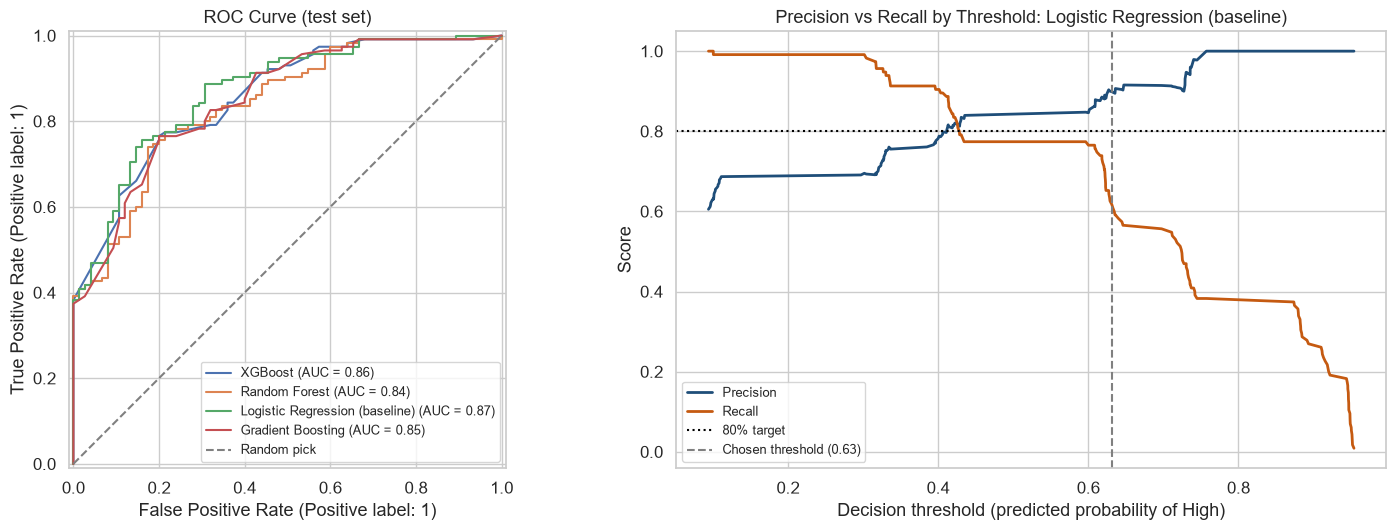

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for name in cv_results.index:
    RocCurveDisplay.from_estimator(models[name], X_test, y_test, name=name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Random pick")
axes[0].set_title("ROC Curve (test set)")
axes[0].legend(fontsize=9, loc="lower right")

proba_best = models[BEST].predict_proba(X_test)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, proba_best)
axes[1].plot(thr, prec[:-1], label="Precision", color=PALETTE["High"], lw=2)
axes[1].plot(thr, rec[:-1], label="Recall", color=ACCENT, lw=2)
axes[1].axhline(TARGET_PRECISION, color="black", ls=":", label="80% target")
axes[1].axvline(thresholds[BEST], color="gray", ls="--", label=f"Chosen threshold ({thresholds[BEST]:.2f})")
axes[1].set_xlabel("Decision threshold (predicted probability of High)")
axes[1].set_ylabel("Score")
axes[1].set_title(f"Precision vs Recall by Threshold: {BEST}")
axes[1].legend(fontsize=9, loc="lower left")
plt.tight_layout()
plt.show()

**Insight**

- **Left:** all ROC curves lie well above the diagonal (random pick) and almost on top of each other (AUC 0.84–0.87). The models rank recipes far better than chance, and none is clearly superior.
- **Right:** precision rises steadily as the threshold increases, while recall falls. At the chosen threshold of 0.63, precision is around 0.90 and recall around 0.6. The product team can **move this threshold** to suit its needs: lower it when more candidate recipes are needed, raise it when the homepage must be as safe as possible.

### 7.3 Confusion Matrix of the Selected Model

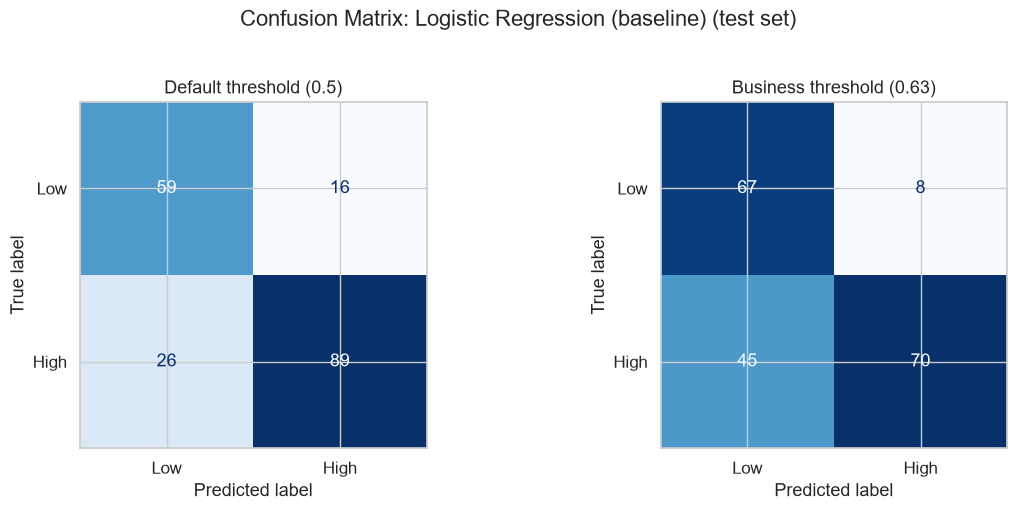

In [27]:
pred_best = (proba_best >= thresholds[BEST]).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, (proba_best >= 0.5).astype(int), display_labels=["Low", "High"],
                                        cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Default threshold (0.5)")
ConfusionMatrixDisplay.from_predictions(y_test, pred_best, display_labels=["Low", "High"],
                                        cmap="Blues", colorbar=False, ax=axes[1])
axes[1].set_title(f"Business threshold ({thresholds[BEST]:.2f})")
fig.suptitle(f"Confusion Matrix: {BEST} (test set)", y=1.02)
plt.tight_layout()
plt.show()

In [28]:
# 95% bootstrap confidence interval for test precision at the business threshold
rng = np.random.default_rng(RANDOM_STATE)
yt, yp = y_test.values, pred_best
boot = [precision_score(yt[i], yp[i], zero_division=0)
        for i in (rng.integers(0, len(yt), len(yt)) for _ in range(2000))]
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Test precision: {precision_score(yt, yp):.3f} | 95% CI: [{lo:.3f}, {hi:.3f}]")

Test precision: 0.897 | 95% CI: [0.826, 0.958]


**Insight: what the confusion matrix means for the homepage**

| | Default (0.5) | Business threshold (0.63) |
|---|---|---|
| Recommended & truly High (TP) | 89 | 70 |
| Recommended but actually Low (FP), *wasted homepage days* | 16 | **8** |
| Precision | 0.85 | **0.90** |

Moving to the business threshold **halves the number of "wasted" homepage recommendations** (16 → 8), at the cost of skipping some recipes that would also have been popular. The skipped recipes are not shown, so they cost nothing.

With only 190 test recipes there is some uncertainty: the bootstrap 95% interval for precision is **[0.83, 0.96]**, entirely above the 80% target, so the result is not a lucky draw.

### 7.4 What Drives the Prediction

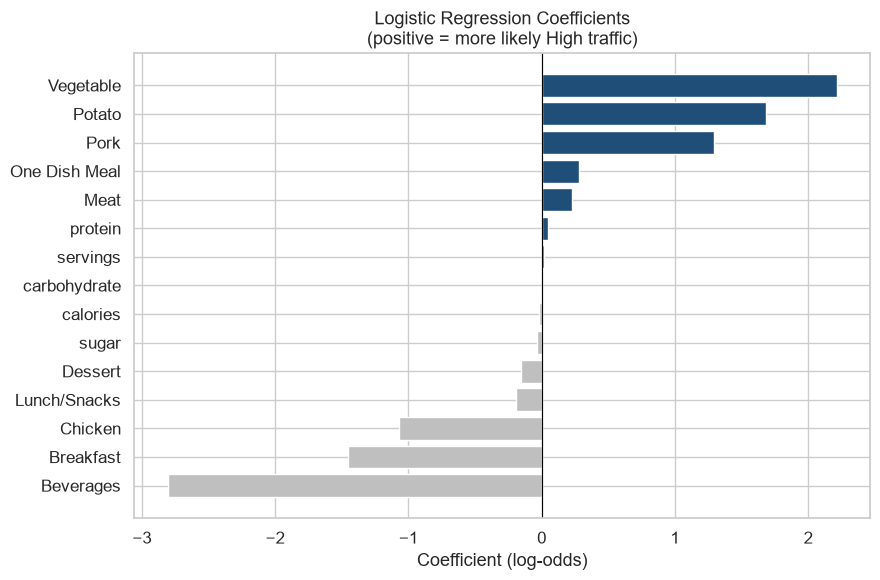

In [29]:
lr = models[BASE]
feat_names = (NUTR_COLS + ["servings"]
              + [c.replace("category_", "") for c in
                 lr.named_steps["prep"].named_transformers_["cat"].get_feature_names_out(["category"])])
coefs = pd.Series(lr.named_steps["model"].coef_[0], index=feat_names).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(coefs.index, coefs.values, color=[PALETTE["High"] if v > 0 else "#bfbfbf" for v in coefs.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Logistic Regression Coefficients\n(positive = more likely High traffic)")
ax.set_xlabel("Coefficient (log-odds)")
plt.tight_layout()
plt.show()

**Insight:** the model confirms the EDA and is easy to explain.

- **Strongest positive drivers:** Vegetable, Potato and Pork recipes greatly increase the chance of high traffic, followed by One Dish Meal and Meat.
- **Strongest negative drivers:** Beverages, Breakfast and Chicken recipes strongly reduce the chance.
- **Nutrition and servings** have very small coefficients. Protein has a small positive effect and sugar a small negative one, so within a category, heartier and less sugary recipes do slightly better.

*Business takeaway:* the **type of recipe** matters far more than its exact nutrition. This can inform which recipes the content team should develop and feature.

### 7.5 Business KPI: Homepage Hit Rate

**KPI definition: Homepage Hit Rate** = share of days on which the recipe shown on the homepage generates high traffic.

- **Current process / random pick:** roughly the base rate of High recipes.
- **Model-guided pick:** show only recipes whose predicted probability is above the business threshold, ranked by probability.

The KPI is easy to monitor every day and links directly to the product manager's 80% goal.

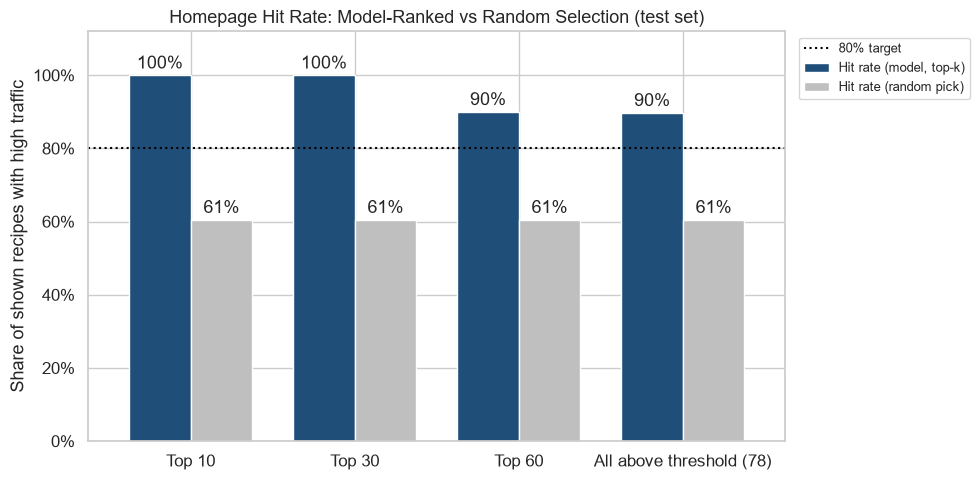

,"Hit rate (model, top-k)",Hit rate (random pick)
Top 10,1.00,0.61
Top 30,1.00,0.61
Top 60,0.90,0.61
All above threshold (78),0.90,0.61


In [30]:
ranked = pd.DataFrame({"proba": proba_best, "actual": y_test.values}).sort_values("proba", ascending=False)
top_k = [10, 30, 60, int(pred_best.sum())]
kpi = pd.DataFrame({
    "Hit rate (model, top-k)": [ranked["actual"].head(k).mean() for k in top_k],
    "Hit rate (random pick)": y_test.mean(),
}, index=[f"Top {k}" for k in top_k[:-1]] + [f"All above threshold ({top_k[-1]})"])

ax = kpi.plot(kind="bar", figsize=(10, 5), color=[PALETTE["High"], "#bfbfbf"], width=0.75)
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v:.0%}" for v in c.datavalues], padding=2)
ax.axhline(TARGET_PRECISION, color="black", ls=":", label="80% target")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 1.12)
ax.set_title("Homepage Hit Rate: Model-Ranked vs Random Selection (test set)")
ax.set_ylabel("Share of shown recipes with high traffic")
plt.xticks(rotation=0)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
plt.tight_layout()
plt.show()
kpi

**Insight:** this chart shows the value in terms the business uses.

- If the homepage showed the **top 30 recipes ranked by the model** (about one month of daily picks), **100%** of them would have been high-traffic, compared with **61%** for a random pick.
- Across all 78 recipes above the threshold, the hit rate is still **90%**, well above the 80% target.

Since popular recipes lift site traffic by up to 40%, moving the hit rate from ~61% to ~90% means **about 9 more high-traffic days per month**, and more subscriptions with them.

## 8. Conclusion & Recommendations

**Conclusion**

- A simple **Logistic Regression** model predicts high-traffic recipes with **0.90 precision** on unseen recipes (95% CI 0.83–0.96), well above the **80% target** and the **61%** hit rate of a pick without a data signal.
- **Recipe category** is the main driver of traffic. Vegetable, Potato and Pork recipes are almost always popular; Beverages, Breakfast and Chicken mostly are not. Nutrition and servings add only small refinements.
- More complex models (Random Forest, Gradient Boosting, XGBoost) do not beat the baseline in a meaningful way, so the simpler and more explainable model is preferred.

**Recommendations**

1. **Use the model as a decision aid.** Pick the homepage recipe from candidates scored above the business threshold (0.63), ranked by probability.
2. **Track the Homepage Hit Rate** weekly against the 80% target.
3. **Run a 4–6 week A/B test** of model-guided selection against manual selection, measuring traffic and subscriptions.
4. **Rotate within the top categories** to avoid homepage fatigue, and **collect richer data** (actual traffic numbers, cooking time, season, images) to improve the model.